# Data Descriptive of YouNiverse

In [1]:
import sys
import os
# This finds the directory *above* 'tests', which is your project root.
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

if project_root not in sys.path:
    sys.path.insert(0, project_root)


# Imports
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patheffects as patheffects
from scipy.stats import mannwhitneyu

from src.data.loader import load_all_raw_datasets, iterate_parquet_stream
from src.data.preprocessing import apply_data_processing
from src.data.quality_check import check_data_quality_on_datasets
from src.models.log_log_efficiency_model import linear_log_log_model
from src.utils.general_utils import weighted_percentiles
from src.utils.paths import (
    DATASET_CHANNELS,
    DATASET_TIMESERIES,
    DATASET_VIDEO_LIGHT,
    PROCESSED_DATA_DIR,
)
from src.utils.plots import *

# Style
sns.set_style("whitegrid")
sns.set_palette("husl")
seed = 6 # for reproducing the results

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

### II. Checking the processed data

In [2]:
channel_df = pd.read_parquet(DATASET_CHANNELS)
channel_df.head(6)

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,0.041988,2.345148e+10,3449869.0,950538161.0,24615813.0,72904068.0,0.982724,3927
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,4804.0,0.095337,0.002954,4.323417e+10,519007.0,96951076.0,55216214.0,611177.0,0.633412,462
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,4785.0,6.825705,0.004994,4.075935e+10,30501034.0,139097733.0,21976958.0,5557559.0,0.861188,23903
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,1076.0,3.337361,0.011340,1.596080e+10,3383229.0,109974549.0,13606395.0,4506589.0,0.904908,3624
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,4552.0,9.538884,0.015842,3.624948e+10,7868933.0,330247613.0,18966387.0,19107723.0,0.939069,40549
5,Entertainment,2007-01-15,UCIwFjwMjI0y7PDBVEO9-bkQ,Justin Bieber,46574085,134,12.0,2.087,4668.0,0.028706,0.025269,5.886436e+08,17697.0,8815774.0,373636.0,719646.0,0.957442,128


In [3]:
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)
timeseries_df.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled,posting_pace_4w,posting_consistency_4w,posting_pace_8w,posting_consistency_8w,posting_pace_12w,posting_consistency_12w
0,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-01,62524.500,4113.500,1466.000,0.000,29,0,1,2016-07-26,0.049820,0.049820,0.0,0.000000,0.0,0.000000,0.0,0.000000
1,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-08,67600.250,5075.750,1508.625,42.625,30,1,2,2016-08-02,0.049374,0.049374,0.0,1.000000,0.0,1.000000,0.0,1.000000
2,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-15,69982.000,2381.750,1530.750,22.125,31,1,2,2016-08-09,0.045413,0.045413,0.0,0.000000,0.0,0.000000,0.0,0.000000
3,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-22,72663.125,2681.125,1558.625,27.875,32,1,2,2016-08-16,0.046415,0.046415,1.0,0.000000,1.0,0.000000,1.0,0.000000
4,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-29,75093.000,2429.875,1591.000,32.375,33,1,2,2016-08-23,0.031169,0.031169,1.0,0.333333,1.0,0.087129,1.0,0.087129


In [13]:
timeseries_df.columns

Index(['channel', 'category', 'datetime', 'views', 'delta_views', 'subs',
       'delta_subs', 'videos', 'delta_videos', 'activity', 'week_start',
       'efficiency_4week', 'efficiency_4week_filled'],
      dtype='object')

In [23]:
# Example of reading from videos_light_processed.parquet with chunks
for df_chunk in iterate_parquet_stream(DATASET_VIDEO_LIGHT, window_size=20_000_000):
    print(df_chunk.shape)

(20054016, 11)
++ Chunk 000: rows 0-20,054,016 | total=20,054,016
(20054016, 11)
++ Chunk 001: rows 20,054,016-40,108,032 | total=40,108,032
(20054016, 11)
++ Chunk 002: rows 40,108,032-60,162,048 | total=60,162,048
(12762746, 11)
++ Final chunk: rows 60,162,048-EOF | rows=12,762,746


# 4. Detecting Outperformers - Research Queston 1

### I. Identifying small to mid sized channels

We define our focus cohort as channels with 10 000–100 000 subscribers. The subscriber distribution is heavy-tailed: the median (P50) is ≈ 22 k and P90 is ≈ 160 k, so 100 k lies well below the top decile while meaningfully above the median. We use 100 k because it:
- aligns with YouTube’s Silver Creator milestone,
- avoids dominance by a small set of very large channels and
 - provides a large, comparable sample of growing creators.

In [5]:
small_mid_sized_channels_df = channel_df[channel_df["subscribers_cc"] < 100_000].copy()

### II. Fitting the Model and Detecting the Outperformers

Outperformers are defined as small- to mid-sized channels that achieve an engagement efficiency substantially higher than what is expected for their subscriber size and category, after controlling for the heavy-tailed scaling of engagement on YouTube.

Starting from the efficiency metric that we defined in feature engineering, we continue with:

- **Expected Efficiency Model (Log–Log Linear Regression)**
  To understand how efficiency scales with channel size, we fit a log–log regression:
  $$
  \log_{10}(E_c) = a + b \, \log_{10}(\text{subscribers}_c) + \varepsilon_c
  $$
  Using logs stabilizes the heavy-tailed data and makes the relationship approximately linear.

- **Residual Efficiency (Deviation from Expectation)**
  The residual measures how much a channel over- or under-performs relative to its expected efficiency:
  $$
  r_c = \log_{10}(E_c) - \big(a + b \, \log_{10}(\text{subscribers}_c)\big)
  $$

- **Quiet Outperformers**
  Channels with residuals above a threshold \( \gamma \) (e.g., mean + 2·std or the top 5%) are labeled as outperformers:
  $$
  r_c > \gamma \;\Rightarrow\; \text{quiet outperformer}
  $$

In [6]:
channels_model = linear_log_log_model(
    df=small_mid_sized_channels_df,
    x_col="subscribers_cc",
    y_col="avg_engagement_efficiency",
    weight_col="weights",
    log_base=10,
    verbose=True,
)

channels_model.head(5)

log–log model fitted: log(y) = -0.9058 + -0.1419 * log(x)


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,log_x,log_y,pred_log_y,residual,zscore
25085,People & Blogs,2016-07-04,UC7wnYvoFWmX-Ad6Az7BsiDQ,NinaUnrated VLOGS,98200,22,78696.0,3.6480,1210.0,0.018182,...,174949.0,2266.0,29914.0,0.986781,16,4.992111,-1.164280,-1.613989,0.449709,1.233636
26369,Music,2018-05-13,UCCjlZHOg6TWQmJ4k3esGxCg,Kevser Öz,92300,264,83140.0,4.2195,532.0,0.496241,...,216481.0,19153.0,13512.0,0.978910,267,4.965202,-1.488122,-1.610172,0.122050,0.341271
26531,People & Blogs,2010-09-08,UC5H8PC7IVxeicx5x5p8roWA,Casi Davis,98683,32,84226.0,4.3250,3336.0,0.009592,...,199670.0,5360.0,8565.0,0.965106,35,4.994242,-1.531054,-1.614292,0.083238,0.235570
26730,People & Blogs,2018-05-02,UCDGY6cFaZKjlY1bguFZHdeQ,Nidal Wonder,98202,45,85347.0,4.4395,543.0,0.082873,...,299536.0,13301.0,12879.0,0.970602,52,4.992120,-1.529482,-1.613991,0.084508,0.239030
26751,Film and Animation,2011-07-30,UC5du0zGwGLWhMAJkLmltGpg,iCraft,92800,69,85414.0,4.4265,3011.0,0.022916,...,232189.0,17840.0,2423.0,0.899380,70,4.967548,-1.824856,-1.610505,-0.214352,-0.574900


The residual distribution is approximately bell-shaped but slightly right-skewed, reflecting that most channels perform near their expected efficiency while a small subset achieve substantially higher engagement relative to size.
We define outperformers as those above the 97th percentile, representing the top 3% of channels with the largest positive deviations.
This stricter cutoff filters out statistical noise and highlights genuinely exceptional channels whose audience engagement is consistently beyond what their subscriber base would predict.

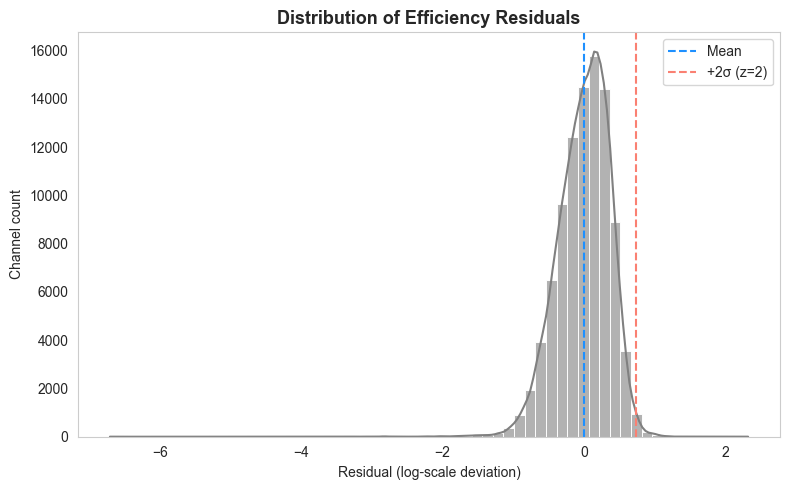

In [7]:
gamma = np.percentile(channels_model["residual"], 97)
plot_residual_distribution(channels_model["residual"])

In [8]:
is_outperformer_mask = channels_model["residual"] > gamma
channel_df["is_outperformer"] = is_outperformer_mask.reindex(channel_df.index, fill_value=False)


In [9]:
outperformers_df = channel_df[channel_df['is_outperformer']]
non_outperformers_df = channel_df=[~channel_df['is_outperformer']]
print(len(outperformers_df))
outperformers_df.head(6)

2831


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,is_outperformer
27568,Music,2012-06-17,UCGnEWsLelLFqMkWcb8s7-nA,孤独なghost,93200,121,88557.0,3.9875,2688.0,0.045015,0.105720,9817455.0,25500.0,845110.0,3881.0,10345.0,0.996371,125,True
29460,People & Blogs,2016-11-05,UCwpAYjmPdYVw6ZNoiul8g2Q,Muhammad Arbaz Offic...,84050,175,95847.0,3.7155,1086.0,0.161142,0.161395,4066492.0,68508.0,303546.0,20696.0,65870.0,0.968095,181,True
30591,Gaming,2019-01-16,UCrDEwtROpcijOFP9uMwz19Q,Parallel Samzyy,79100,40,99714.0,3.7395,284.0,0.140845,0.098866,6788720.0,9521.0,604033.0,11725.0,10072.0,0.979401,51,True
32883,Pets & Animals,2015-12-16,UCkrkMMAyxC9vGNa6ZJYyscg,Takis Shelter - The ...,73600,316,109765.0,5.0415,1411.0,0.223955,0.151517,22679099.0,91716.0,1207584.0,9496.0,104127.0,0.995255,340,True
32943,Gaming,2011-09-27,UC3-8qZ-rZvlSVWwkHoeelCA,TheMythicalSausage,83000,1766,110160.0,5.0940,2952.0,0.598238,0.094543,12100847.0,3513327.0,416318.0,7942.0,87631.0,0.979128,1773,True
33055,Gaming,2019-04-17,UCaH2302aYnmOJH-CWn-Bebg,Military Dave,84100,52,110730.0,4.9860,193.0,0.269430,0.110061,2810462.0,21462.0,304313.0,17771.0,30004.0,0.864303,55,True


In [18]:
import plotly.graph_objects as go

df = channels_model.copy()
gamma = np.percentile(df["residual"], 97)
df["is_outperformer"] = df["residual"] > gamma

fig = go.Figure()

# Base channels
fig.add_trace(go.Scattergl(
    x=df["pred_log_y"],
    y=df["residual"],
    mode="markers",
    name="Channels",
    marker=dict(size=5, color="rgba(150,150,150,0.3)"),
    hovertemplate="<b>%{customdata[0]}</b><br>Pred log-eff: %{x:.3f}<br>Residual: %{y:.3f}<extra></extra>",
    customdata=np.stack([df["name_cc"]], axis=-1)
))

# Outperformers
out = df[df["is_outperformer"]]
fig.add_trace(go.Scattergl(
    x=out["pred_log_y"],
    y=out["residual"],
    mode="markers",
    name="Outperformers",
    marker=dict(size=7, color="#8A2BE2"),
    hovertemplate="<b>%{customdata[0]}</b> ⭐<br>Pred log-eff: %{x:.3f}<br>Residual: %{y:.3f}<extra></extra>",
    customdata=np.stack([out["name_cc"]], axis=-1)
))

# Horizontal line at 0
fig.add_hline(y=0, line=dict(color="green", width=2))

fig.update_layout(
    title="Residual Plot: Observed vs Expected Efficiency",
    xaxis=dict(title="Predicted log-Efficiency"),
    yaxis=dict(title="Residual (Observed - Expected)"),
    template="plotly_white"
)

fig.show()


#### III. Categories of quiet outperformers

Initially, dataset provides us a correspondence of each channel to 1 of 15 predefined categories. Let's see, how quiet outperformers are distributed by those categories and how they relate to overall distribution of categories among all channels.

_Note: those categories can be then upgraded by using some additional metadata about videos, such as tags or description data. We explore this on Research Question 2._

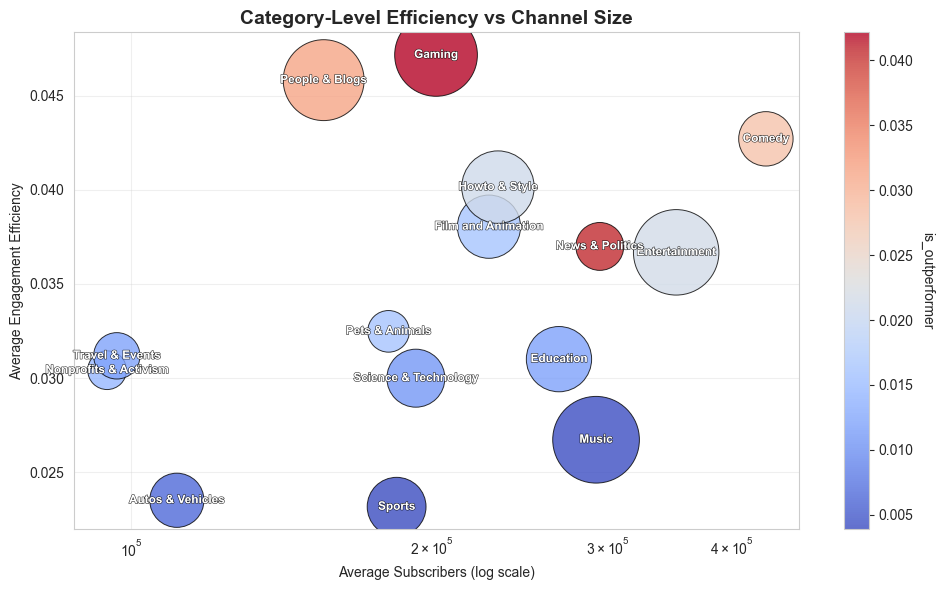

In [83]:
plot_category_bubble(
    df=channel_df,
    size_col="subscribers_cc",
    value_col="avg_engagement_efficiency",
    category_col="category_cc",
    color_col="is_outperformer",  # average will give share of outperformers
    title="Category-Level Efficiency vs Channel Size",
    xlabel="Average Subscribers (log scale)",
    ylabel="Average Engagement Efficiency",
)

#### IV. Diving into one Outperformer

Let’s take a closer look at one of the top quiet outperformers, the channel “Gym Monk / Gaming.”
This channel still exists today with around 28K subscribers, and during the 2019 period it had multiple videos reaching hundreds of thousands of views.

In [86]:
# Loading the time series data
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)

In [17]:
channel = 'UCfs20O_RuLJXGGTxv5VIzdw'
channel_timeseries = timeseries_df[timeseries_df['channel'] == channel]
channel_timeseries.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
12899150,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-04-25,26360.750,63.750,1775.750,0.000,77,0,11,2016-04-19,1.208036,1.208036
12899151,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-02,26807.000,446.250,1795.000,19.250,77,0,6,2016-04-26,NaN,NaN
12899152,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-09,27071.250,264.250,1806.375,11.375,78,1,1,2016-05-03,1.193830,1.193830
12899153,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-16,27407.500,336.250,1814.750,8.375,80,2,3,2016-05-10,1.154780,1.154780
12899154,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-23,28045.125,637.625,1830.125,15.375,84,4,6,2016-05-17,0.880374,0.880374


Let's compare his efficiency(outperformer) to someone who is in the same category "Gaming" and has an average efficiency.


In [31]:
target_channel = "UCfs20O_RuLJXGGTxv5VIzdw"
target_eff = channel_df.loc[channel_df["channel"] == target_channel, "avg_engagement_efficiency"].iloc[0]

# Find average efficiency for Gaming category
avg_eff_gaming = (
    channel_df.loc[channel_df["category_cc"] == "Gaming", "avg_engagement_efficiency"]
    .mean()
)

# Find channel in Gaming closest to that average
avg_channel = (
    channel_df[channel_df["category_cc"] == "Gaming"]
    .assign(diff=lambda x: (x["avg_engagement_efficiency"] - avg_eff_gaming).abs())
    .sort_values("diff")
    .iloc[0]
)

avg_channel_id = avg_channel["channel"]
avg_channel_eff = avg_channel["avg_engagement_efficiency"]

print(f"Matched 'average' Gaming channel: {avg_channel_id}")

Matched 'average' Gaming channel: UCRZ5-H-PV_2jsj3JsB9uU2A


In [34]:
channel_2 = 'UCRZ5-H-PV_2jsj3JsB9uU2A'
channel_timeseries_2 = timeseries_df[timeseries_df['channel'] == channel_2]
channel_timeseries_2.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
8395116,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-02,178813.500,751.500,831.000,0.000,5,0,0,2016-04-26,NaN,NaN
8395117,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-09,180609.500,1796.000,837.750,6.750,5,0,0,2016-05-03,NaN,NaN
8395118,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-16,182562.375,1952.875,845.125,7.375,6,1,1,2016-05-10,0.012577,0.012577
8395119,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-23,184819.000,2256.625,860.000,14.875,7,1,2,2016-05-17,0.010054,0.010054
8395120,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-30,186508.625,1689.625,867.000,7.000,8,1,2,2016-05-24,0.015791,0.015791


H₀ (null hypothesis):
The outperformer’s engagement efficiency over time is not significantly different from that of an average Gaming channel.

H₁ (alternative hypothesis):
The outperformer’s engagement efficiency is significantly higher than that of an average Gaming channel.

In [42]:
# Drop missing values
eff_out = target_ts["efficiency_4week_filled"].dropna()
eff_avg = avg_ts["efficiency_4week_filled"].dropna()

# Mann-Whitney U test (one-sided: outperformer > average)
stat, p_value = mannwhitneyu(eff_out, eff_avg, alternative="greater")

print(f"Mann–Whitney U statistic: {stat:.3f}")
print(f"p-value: {p_value:.6f}")

Mann–Whitney U statistic: 7840.000
p-value: 0.000000


To assess whether the outperformer’s engagement efficiency is statistically higher than that of a typical Gaming channel, we performed a one-sided Mann–Whitney U test on their weekly efficiency distributions.
The test yielded a U statistic of 7840 and a p-value < 0.000001, allowing us to reject the null hypothesis of equal engagement levels.
This confirms that the outperformer’s audience interacts significantly more per view than viewers of a comparable average Gaming channel.

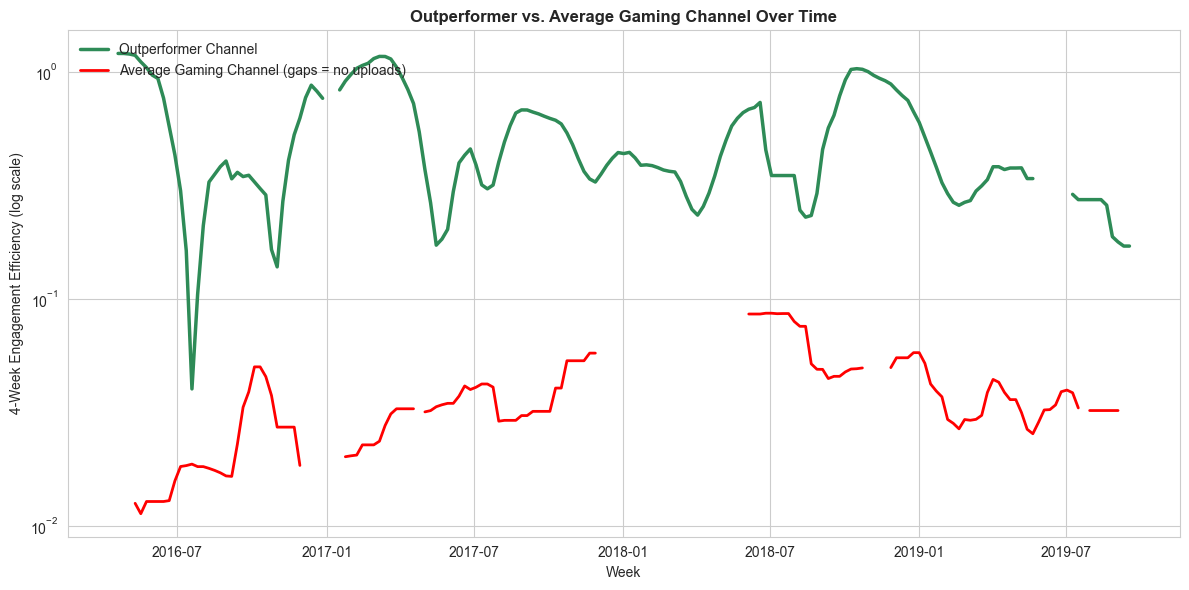

In [40]:
plot_channel_comparison(
    df=timeseries_df,
    target_channel=target_channel,
    avg_channel_id=avg_channel_id,
)

As expected, the outperformer channel achieves consistently higher engagement efficiency than the average Gaming channel throughout the observed period.
Additionally, the outperformer shows fewer and shorter inactivity gaps, indicating a more consistent upload pattern and sustained audience engagement over time.


These observations motivate our subsequent research questions. Having established that a quiet outperformer achieves consistently higher engagement efficiency and more stable activity than a comparable average Gaming channel, we next ask whether this pattern generalizes across the platform. Specifically, we investigate how quiet outperformers are distributed across content communities (RQ2), which structural or strategic choices, such as posting frequency, duration, or timing, are statistically associated with higher efficiency within each size tier and content type (RQ3), and finally, whether quiet outperformers sustain more stable growth in views and subscribers compared to similar non-outperforming channels (RQ4). Together, these questions aim to uncover the structural and behavioral factors that differentiate quiet outperformers from typical creators beyond raw engagement metrics.

## 5. Mathematical model of Research Questions

### RQ2: Are quiet outperformers concentrated in particular content categories, or do their engagement efficiency patterns vary across categories?

---

#### 1. Choice of Content Categorization

We consider two approaches to define a channel's content category: (a) Using YouTube's 15 official categories, (b) Using data-driven clusters
To better capture real content communities, we construct data-driven clusters from video-level textual data (tags).

#### 2. Building Data-Driven Content Clusters

##### 2.1 Text Preprocessing
For each video:
1. Clean tags text:
   - lowercase
   - remove punctuation, stopwords, and numbers
   - lemmatize or stem words
2. Join all tags into one document string per video.


##### 2.2 Text Representation
We represent each video's tags as a mixture of latent topics using **Latent Dirichlet Allocation (LDA)**, a probabilistic topic modeling approach.
LDA assumes that:
- each video's tag set is generated from a mixture of *K* latent topics, and
- each topic is a probability distribution over words.

Formally, for each video *v* (treated as a “document” of tags):

$$
\theta_v \sim \text{Dirichlet}(\alpha), \quad \phi_k \sim \text{Dirichlet}(\beta)
$$

where
- $\theta_v = (\theta_{v1}, \theta_{v2}, ..., \theta_{vK})$ represents the topic proportions for video *v*,
- $\phi_k$ is the word distribution for topic *k*,
- $\alpha$ and $\beta$ are Dirichlet hyperparameters controlling sparsity.

Each tag $w_{vn}$ in video *v* is generated by:
$$
z_{vn} \sim \text{Multinomial}(\theta_v), \quad w_{vn} \sim \text{Multinomial}(\phi_{z_{vn}})
$$

After fitting the model, each video is represented by its topic distribution vector:

$$
\theta_v = (\theta_{v1}, \theta_{v2}, ..., \theta_{vK}), \quad \sum_{k=1}^{K} \theta_{vk} = 1
$$

We determine the optimal number of topics *K* using **topic coherence** and **perplexity** metrics.
- Higher coherence indicates more interpretable and distinct topics.
- Lower perplexity indicates better generalization to unseen data.

Each topic is then characterized by its most probable words, and then summarized using a large language model (LLM) for interpretability.

Once trained, we assign each video to its dominant topic:
$$
\text{Topic}(v) = \arg\max_k \theta_{vk}
$$

These inferred topics form data-driven content categories, which are later aggregated to the channel level (next step).

#### 3. Aggregating Clusters to the Channel Level

Because quiet outperformers are defined at the channel level, we aggregate the video clusters as follows:

1. Count the number of videos per cluster for each channel:

    $$
    n_{c,k} = \mathrm{\#\ of\ videos\ from\ channel\ } c \mathrm{\ in\ cluster\ } k
    $$

2. Compute each channel's cluster proportion:

    $$
    p_{c,k} = \frac{n_{c,k}}{\sum_{j} n_{c,j}}
    $$

3. Assign the **dominant cluster**:

    $$
    \text{Cluster}_c = \arg\max_k p_{c,k}
    $$

4. Compute **topic diversity** using Shannon entropy:

    $$
    H_c = -\sum_k p_{c,k} \log(p_{c,k})
    $$

    Channels with high entropy (e.g., $H_c > 1.5$) can be excluded to focus on thematically consistent creators.

#### 4. Comparing Engagement Efficiency Among Quiet Outperformers Across Categories

Let $\hat{\varepsilon}_c$ denote the *residual efficiency* for channel $c$, derived from RQ1, and let $k$ denote its assigned content category or cluster (from YouTube's predefined categories or LDA-derived topics).

##### 4.1 Summary Statistics and Visualization

For each category $k$, compute descriptive statistics among quiet outperformers:
$$
\text{Mean}_k = \frac{1}{n_k} \sum_{c \in k} \hat{\varepsilon}_c, \quad
\text{Median}_k, \quad \text{IQR}_k, \quad \text{SD}_k
$$

Visualize the efficiency distributions across categories using **violin plots**, **boxplots**, or **kernel density plots** (KDE).
These visuals reveal whether outperformers from certain content types (e.g., Education, Gaming, Lifestyle) tend to achieve systematically higher engagement efficiency.

##### 4.2 Testing Differences in Efficiency Distributions

To formally test whether efficiency distributions differ across categories, apply the **Kruskal-Wallis H test**:

$$
H_0: f_1(\hat{\varepsilon}) = f_2(\hat{\varepsilon}) = \dots = f_K(\hat{\varepsilon})
$$

$$
H = \frac{12}{N(N+1)} \sum_{k=1}^{K} n_k (\bar{R}_k - \bar{R})^2
$$

where:
- $n_k$ = number of outperformers in category $k$
- $\bar{R}_k$ = mean rank of efficiency in category $k$
- $\bar{R}$ = mean rank overall
- $N$ = total number of outperformers

If $p < 0.05$, we reject $H_0$ and conclude that at least one content category of outperformers exhibits a distinct engagement efficiency distribution.

If the global test is significant, perform Dunn's post-hoc tests with False Discovery Rate correction to identify which categories differ.


##### 4.3 Concentration of Outperformers Across Categories

To assess whether quiet outperformers are disproportionately represented in certain content types, compare the observed vs. expected counts of outperformers per category using a **Chi-square goodness-of-fit test**:

$$
\chi^2 = \sum_{k=1}^{K} \frac{(O_k - E_k)^2}{E_k}
$$

where:
- $O_k$ = observed number of outperformers in category $k$
- $E_k$ = expected number based on overall category proportions in the full dataset

A significant result ($p < 0.05$) indicates that outperformers are concentrated in specific content categories rather than evenly distributed.



### RQ3:

---

### RQ4:

---